# Market Regime Detection & Regime-Conditional VaR

Markets spend long stretches in calm and short bursts in turmoil, and in turmoil volatility jumps and diversification disappears. A risk model calibrated on average conditions is too cautious in quiet times and too optimistic at the start of a crisis. This notebook identifies the market's regimes and builds a VaR that adapts to the one the market is in.

**What it does.** It identifies calm, normal and stressed market regimes from weekly market data, shows how long they last and how they switch, and uses the regime probabilities to build a VaR that adapts to the state of the market, backtested out of sample.

**Data.** Daily total-return prices of an eight-ETF multi-asset portfolio (Yahoo Finance), and the VIX and the Moody's Baa credit spread (FRED), all since 2007.

**Methods.** Gaussian hidden Markov models with 2–5 states chosen by BIC, a Gaussian mixture as a benchmark without memory, and forward filtering without look-ahead.

The VaR is a mixture weighted by the predicted regime probabilities, compared with historical-simulation and EWMA VaR.

**Key output.** The regime timeline since 2007, regime statistics and the transition matrix, the current regime probabilities, and an out-of-sample weekly VaR backtest for 2017–2026.

## 1. Why regimes

Markets alternate between long quiet stretches and short turbulent ones. In stress, volatility jumps, correlations rise and diversification disappears. A risk model calibrated on "average" data is too conservative in calm times and too optimistic at the start of a crisis. A **regime model** gives the risk officer two things:

1. **A label for today:** "we are 85% likely in a stressed regime" is a concise input for limit setting, stress testing and the risk appetite discussion.
2. **A conditional risk forecast:** next week's loss distribution is a mixture of the regimes' distributions, weighted by how likely each regime is next week.

The hidden Markov model (HMM) does both. It assumes an unobserved state $s_t$ that follows a Markov chain, and observations that are Gaussian given the state.

## 2. The model

**Gaussian HMM:** $P(s_{t+1}=j \mid s_t=i) = A_{ij}$, and $x_t \mid s_t = k \sim \mathcal{N}(\mu_k, \Sigma_k)$, where $x_t$ is the weekly feature vector. Parameters come from the EM (Baum–Welch) algorithm, with several random starts.

**Filtering, not smoothing.** The standard "posterior state probabilities" use the whole sample, future included. For an honest backtest we run the **forward filter** with parameters estimated on 2007–2016 only:
$$
p_{t\mid t}(k) \propto f_k(x_t)\sum_i p_{t-1\mid t-1}(i)\,A_{ik}, \qquad p_{t+1\mid t} = p_{t\mid t}\,A .
$$

**Regime-conditional VaR.** Each regime $k$ has its own distribution of portfolio returns $F_k$. Next week's VaR is the quantile of the mixture:
$$
\sum_k p_{t+1\mid t}(k)\,F_k(-\text{VaR}_{t+1}) = \alpha .
$$

**Choosing the number of regimes:** $\text{BIC} = -2\ln L + p\ln T$, with $p$ the number of free parameters.

## 3. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import yfinance as yf
from hmmlearn.hmm import GaussianHMM
from scipy import stats
from scipy.optimize import brentq
from sklearn.mixture import GaussianMixture
import logging

# EM convergence chatter at 1e-6 precision
logging.getLogger("hmmlearn").setLevel(logging.ERROR)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

WEIGHTS = {
    "SPY": 0.30,
    "IWM": 0.10,
    "EFA": 0.10,
    "TLT": 0.15,
    "IEF": 0.10,
    "LQD": 0.10,
    "HYG": 0.10,
    "GLD": 0.05,
}
TICKERS = list(WEIGHTS)
START = "2007-01-01"
# parameters estimated on 2007–2016; 2017 onwards is out of sample
TRAIN_END = "2016-12-31"
STATES = range(2, 5)
N_STARTS = 8
VAR_LEVELS = (0.95, 0.99)
PORTFOLIO_USD = 100_000_000
SEED = 17

print(f"run on {dt.date.today():%Y-%m-%d}")

run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


REGIME_COLORS = [PALETTE[2], PALETTE[0], PALETTE[3], STATUS["red"], PALETTE[6]]

## 4. Data and weekly features

Four weekly features (Friday to Friday) describe the market's state:

| Feature | Why |
|---|---|
| S&P 500 (SPY) weekly return | direction |
| log realised volatility of SPY within the week | turbulence now |
| log VIX at the week's close | expected turbulence |
| 4-week change in the Moody's Baa – 10Y Treasury spread (FRED `BAA10Y`) | credit stress building up |

The credit spread enters as a *change*: its level drifts over decades, and in levels the model would learn eras rather than regimes.

The portfolio is a USD 100 mm multi-asset mix of eight ETFs, rebalanced daily.

In [3]:
def fetch_prices():
    px = yf.download(TICKERS, start=START, auto_adjust=True, progress=False)[
        "Close"
    ]
    if isinstance(px, pd.Series):
        px = px.to_frame(TICKERS[0])
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.index.name, px.columns.name = "date", None
    return px[TICKERS].reset_index()


prices = cached("yahoo_prices", fetch_prices).set_index("date").sort_index()
# completed sessions only (no intraday row)
prices = prices[prices.index < pd.Timestamp.today().normalize()]
prices = prices.dropna(how="all").ffill(limit=3)

# --- Data cleaning: one-day bad prints that reverse the next day are replaced
# by interpolation
raw_ret = np.log(prices).diff()
# robust daily sigma
scale = raw_ret.abs().rolling(120, min_periods=40).median().shift() / 0.6745
spike = (raw_ret.abs() > 10 * scale) & (
    (raw_ret + raw_ret.shift(-1)).abs() < 0.25 * raw_ret.abs()
)
# A genuine crash-and-rebound (e.g. 12-13 Mar 2020) moves many assets at once;
# a bad print is idiosyncratic.
market_wide = (raw_ret.abs() > 4 * scale).sum(axis=1) >= 3
spike = (
    spike & ~market_wide.values[:, None]
    if prices.shape[1] >= 3
    else spike & False
)
for c in prices.columns[spike.any()]:
    print(
        f"Data fix · {c}: bad print on"
        f" {', '.join(f'{d:%Y-%m-%d}' for d in spike.index[spike[c]])} interpolated"
    )
prices = prices.mask(spike).interpolate(limit_area="inside")
returns = np.log(prices).diff().dropna()
EVAL_DATE = returns.index.max()
print(
    f"{len(returns):,} trading days · {returns.index.min():%Y-%m-%d} →"
    f" {EVAL_DATE:%Y-%m-%d} · {', '.join(prices.columns)}"
)

4,911 trading days · 2007-04-12 → 2026-10-16 · SPY, IWM, EFA, TLT, IEF, LQD, HYG, GLD


In [4]:
def fetch_fred():
    return pd.concat([
        pd.DataFrame({"date": s.index, "series": sid, "value": s.values})
        for sid in ["VIXCLS", "BAA10Y"]
        for s in [fred.get_series(sid, observation_start=START).dropna()]
    ])


macro = (
    cached("fred_vix_baa", fetch_fred)
    .pivot(index="date", columns="series", values="value")
    .sort_index()
)
w = pd.Series(WEIGHTS)[returns.columns].values
# daily portfolio return
port_d = np.expm1(returns) @ w
daily = (
    pd.DataFrame({"spy": returns["SPY"], "port": port_d})
    .join(macro, how="left")
    .ffill()
)

wk = pd.DataFrame({
    "spy_ret": daily["spy"].resample("W-FRI").sum() * 100,
    "log_rv": np.log(
        daily["spy"].resample("W-FRI").std() * np.sqrt(252) * 100
    ),
    "log_vix": np.log(daily["VIXCLS"].resample("W-FRI").last()),
    # bp over four weeks
    "d_credit": daily["BAA10Y"].resample("W-FRI").last().diff(4) * 100,
})
# weekly portfolio return
port_w = (1 + daily["port"]).resample("W-FRI").prod() - 1
wk = wk.join(port_w.rename("port_ret")).dropna()
wk = wk[wk.index <= EVAL_DATE]
FEATS = ["spy_ret", "log_rv", "log_vix", "d_credit"]
train, test = wk.loc[:TRAIN_END], wk.loc[TRAIN_END:].iloc[1:]
mu_f, sd_f = train[FEATS].mean(), train[FEATS].std()
Z = (wk[FEATS] - mu_f) / sd_f
print(
    f"{len(wk)} weeks · train {len(train)} ({train.index.min():%Y-%m-%d} →"
    f" {train.index.max():%Y-%m-%d}) · test {len(test)} (→"
    f" {test.index.max():%Y-%m-%d})"
)
wk.describe().T.round(3)

1015 weeks · train 504 (2007-05-11 → 2016-12-30) · test 510 (→ 2026-10-16)


,count,mean,std,min,25%,50%,75%,max
spy_ret,"1,015.00",0.20,2.54,-22.06,-0.96,0.36,1.51,12.48
log_rv,"1,015.00",2.48,0.69,-0.03,2.00,2.50,2.92,4.93
log_vix,"1,015.00",2.91,0.36,2.21,2.64,2.85,3.12,4.37
d_credit,"1,015.00",-0.09,23.28,-112.00,-10.00,-1.00,8.00,214.00
port_ret,"1,015.00",0.00,0.01,-0.13,-0.01,0.00,0.01,0.10


## 5. How many regimes? HMM vs BIC

In [5]:
Ztr = Z.loc[train.index].values


def fit_hmm(k):
    best = None
    for s in range(N_STARTS):
        m = GaussianHMM(
            n_components=k,
            covariance_type="full",
            n_iter=500,
            tol=1e-5,
            random_state=SEED + s,
        )
        m.fit(Ztr)
        ll = m.score(Ztr)
        if best is None or ll > best[1]:
            best = (m, ll)
    return best


d = len(FEATS)
sel = []
models = {}
for k in STATES:
    m, ll = fit_hmm(k)
    n_par = (k - 1) + k * (k - 1) + k * d + k * d * (d + 1) / 2
    models[k] = m
    sel.append({
        "states": k,
        "log-likelihood": ll,
        "parameters": n_par,
        "BIC": -2 * ll + n_par * np.log(len(Ztr)),
    })
sel = pd.DataFrame(sel).set_index("states")
K = int(sel["BIC"].idxmin())
hmm = models[K]
print(f"BIC picks {K} regimes")
sel.round(1)

BIC picks 4 regimes


,log-likelihood,parameters,BIC
states,,,
2,"-2,103.00",31.00,"4,398.80"
3,"-1,841.20",50.00,"3,993.60"
4,"-1,744.60",71.00,"3,930.90"


### 5.1 Naming the regimes

States are ordered by their mean realised volatility, so state 0 is the calmest. The table shows what each regime looks like in the training years, with each week assigned to its most likely state (smoothed, which is fine *in sample*).

In [6]:
# calm → crisis
order = np.argsort(hmm.means_[:, FEATS.index("log_rv")])
NAMES = {
    2: ["Calm", "Stress"],
    3: ["Calm", "Normal", "Stress"],
    4: ["Calm", "Normal", "Stress", "Crisis"],
}[K]
relabel = {old: new for new, old in enumerate(order)}
A = hmm.transmat_[np.ix_(order, order)]
state_train = np.array([relabel[s] for s in hmm.predict(Ztr)])

stats_rows = []
for k, name in enumerate(NAMES):
    sel_w = train[state_train == k]
    pr = sel_w["port_ret"]
    stats_rows.append({
        "regime": name,
        "% of weeks": len(sel_w) / len(train) * 100,
        "expected duration (weeks)": 1 / (1 - A[k, k]),
        "SPY vol % (avg)": np.exp(sel_w["log_rv"]).mean(),
        "VIX (avg)": np.exp(sel_w["log_vix"]).mean(),
        "Baa spread 4w change bp (avg)": sel_w["d_credit"].mean(),
        "portfolio return % a year": pr.mean() * 52 * 100,
        "portfolio vol % a year": pr.std() * np.sqrt(52) * 100,
        "worst week %": pr.min() * 100,
    })
regimes = pd.DataFrame(stats_rows).set_index("regime")
print("Transition matrix (rows = from, columns = to):")
print(pd.DataFrame(A, index=NAMES, columns=NAMES).round(3).to_string())
regimes.round(2)

Transition matrix (rows = from, columns = to):
        Calm  Normal  Stress  Crisis
Calm    0.94    0.05    0.01    0.00
Normal  0.07    0.86    0.08    0.00
Stress  0.00    0.10    0.87    0.03
Crisis  0.00    0.01    0.03    0.96


,% of weeks,expected duration (weeks),SPY vol % (avg),VIX (avg),Baa spread 4w change bp (avg),portfolio return % a year,portfolio vol % a year,worst week %
regime,,,,,,,,
Calm,34.13,17.52,9.52,13.74,-2.81,7.44,5.89,-3.14
Normal,28.37,7.01,11.66,17.66,-5.80,14.79,6.51,-2.13
Stress,23.02,7.92,19.47,23.97,11.47,0.39,9.46,-3.39
Crisis,14.48,23.91,36.99,39.29,3.23,0.26,21.21,-12.79


## 6. Filtering through time, without look-ahead

The forward filter runs over the full history with the 2007–2016 parameters. From 2017 on, every probability uses only data available at that week's close.

In [7]:
means, covs = hmm.means_[order], hmm.covars_[order]
emis = np.column_stack([
    stats.multivariate_normal(means[k], covs[k], allow_singular=True).logpdf(
        Z.values
    )
    for k in range(K)
])
start = hmm.startprob_[order]
filt = np.zeros((len(Z), K))
p = start
for t in range(len(Z)):
    prior = p @ A if t > 0 else start
    lik = np.exp(emis[t] - emis[t].max())
    post = prior * lik
    p = post / post.sum()
    filt[t] = p
filt = pd.DataFrame(filt, index=Z.index, columns=NAMES)
# p(s_t | info up to t−1)
pred = pd.DataFrame(filt.values @ A, index=Z.index, columns=NAMES).shift(1)

# Benchmark without memory: a Gaussian mixture with the same number of
# components
gmm = GaussianMixture(
    K, covariance_type="full", n_init=N_STARTS, random_state=SEED
).fit(Ztr)
g_order = np.argsort(gmm.means_[:, FEATS.index("log_rv")])
g_state = pd.Series(
    [list(g_order).index(s) for s in gmm.predict(Z.values)], index=Z.index
)
h_state = filt.values.argmax(axis=1)
switches = lambda s: (np.diff(np.asarray(s)) != 0).sum()
print(
    f"Regime switches since 2007: HMM (filtered) {switches(h_state)} · GMM"
    f" {switches(g_state)} · current regime probabilities: "
    + ", ".join(f"{n} {v:.0%}" for n, v in filt.iloc[-1].items())
)

Regime switches since 2007: HMM (filtered) 134 · GMM 292 · current regime probabilities: Calm 5%, Normal 92%, Stress 2%, Crisis 0%


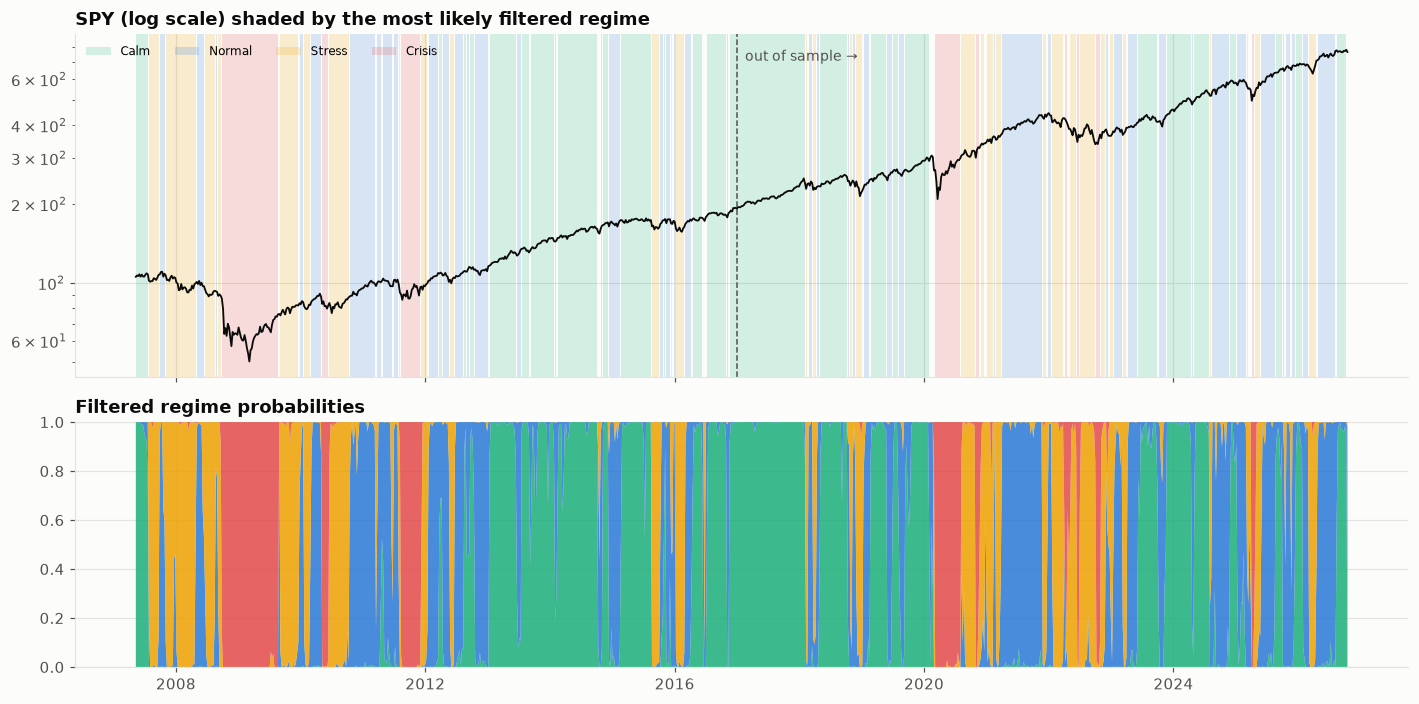

In [8]:
# --- Chart 1: the regime timeline
fig, axes = plt.subplots(
    2,
    1,
    figsize=(13, 6.5),
    sharex=True,
    gridspec_kw={"height_ratios": [1.4, 1]},
)
ax = axes[0]
spy_level = prices["SPY"].resample("W-FRI").last().reindex(Z.index)
for k, name in enumerate(NAMES):
    on = h_state == k
    ax.fill_between(
        Z.index,
        0,
        1,
        where=on,
        transform=ax.get_xaxis_transform(),
        color=REGIME_COLORS[k],
        alpha=0.18,
        lw=0,
        label=name,
    )
ax.plot(spy_level.index, spy_level, color=INK, lw=1.2)
ax.set_yscale("log")
ax.axvline(pd.Timestamp(TRAIN_END), color=INK_2, ls="--", lw=1)
ax.text(
    pd.Timestamp(TRAIN_END),
    spy_level.max(),
    "  out of sample →",
    va="top",
    fontsize=9,
    color=INK_2,
)
ax.set_title("SPY (log scale) shaded by the most likely filtered regime")
ax.legend(ncol=K, fontsize=8, loc="upper left")
ax = axes[1]
ax.stackplot(
    filt.index,
    filt.T.values,
    colors=REGIME_COLORS[:K],
    alpha=0.85,
    labels=NAMES,
)
ax.set_ylim(0, 1)
ax.set_title("Filtered regime probabilities")
plt.tight_layout()
save_fig(fig, "01_regime_timeline")
plt.show()

## 7. Regime-conditional VaR, backtested out of sample

The backtest is walk-forward. **Every January** the HMM and the per-regime return distributions are re-estimated on all data up to the previous December. Each regime's weekly portfolio returns get a Student-t fit, which keeps fat tails inside each regime. During the year, each week's VaR is the quantile of the mixture of these distributions, weighted by the regime probabilities **predicted** from the previous week by the forward filter. Nothing from the future is used.

A first version kept the 2007–2016 parameters fixed. It under-forecast badly after 2022, when the stock–bond correlation flipped and a "calm" regime no longer meant a calm portfolio. Re-estimation is what a production model would do.

A second, **hybrid** model takes the volatility *level* from EWMA (fast) and the *shape* of the tail from the regimes. Weekly returns are standardised by the EWMA volatility, a Student-t is fitted to those standardised returns in each regime, and the regime-weighted quantile is scaled back by today's EWMA volatility.

Benchmarks:

- **Historical simulation:** 156-week (three-year) rolling window.
- **EWMA normal:** RiskMetrics weekly decay 0.85.

The test sample has about 500 weeks, so 95% VaR (about 25 expected exceptions) is the main test; 99% (about 5) is shown for completeness.

In [9]:
R = wk["port_ret"]
# weekly EWMA variance known before week t
s2_ewma = R.pow(2).ewm(alpha=0.15, adjust=False).mean().shift(1)
# returns standardised by EWMA volatility
zret = (R / np.sqrt(s2_ewma)).dropna()


def fit_regime_model(upto):
    """
    Re-estimate the HMM (K states, best of N_STARTS) and the per-regime return
    distributions on data up to `upto`.
    """
    tr = wk.loc[:upto]
    mu_, sd_ = tr[FEATS].mean(), tr[FEATS].std()
    z_tr = ((tr[FEATS] - mu_) / sd_).values
    best = None
    for s_ in range(N_STARTS):
        m_ = GaussianHMM(
            n_components=K,
            covariance_type="full",
            n_iter=500,
            tol=1e-5,
            random_state=SEED + s_,
        ).fit(z_tr)
        ll = m_.score(z_tr)
        if best is None or ll > best[1]:
            best = (m_, ll)
    m_ = best[0]
    o_ = np.argsort(m_.means_[:, FEATS.index("log_rv")])
    rel_ = {old: new for new, old in enumerate(o_)}
    st_ = np.array([rel_[x] for x in m_.predict(z_tr)])
    dists = [stats.t.fit(tr["port_ret"].values[st_ == k]) for k in range(K)]
    z_tr = zret.reindex(tr.index).values
    zdists = [
        stats.t.fit(z_tr[(st_ == k) & ~np.isnan(z_tr)]) for k in range(K)
    ]
    return {
        "zdists": [(max(nu, 2.5), lo, sc) for nu, lo, sc in zdists],
        "mu": mu_,
        "sd": sd_,
        "A": m_.transmat_[np.ix_(o_, o_)],
        "start": m_.startprob_[o_],
        "means": m_.means_[o_],
        "covs": m_.covars_[o_],
        "dists": [(max(nu, 2.5), lo, sc) for nu, lo, sc in dists],
    }


def predicted_probs(model, upto):
    """
    Forward filter on all weeks up to `upto`; returns p(s_t | info up to t-1)
    for every week.
    """
    z = ((wk.loc[:upto, FEATS] - model["mu"]) / model["sd"]).values
    em = np.column_stack([
        stats.multivariate_normal(
            model["means"][k], model["covs"][k], allow_singular=True
        ).logpdf(z)
        for k in range(K)
    ])
    p_, out = model["start"], []
    for t in range(len(z)):
        prior = p_ @ model["A"] if t > 0 else model["start"]
        out.append(prior)
        post = prior * np.exp(em[t] - em[t].max())
        p_ = post / post.sum()
    return pd.DataFrame(out, index=wk.loc[:upto].index)


def mixture_var(probs, dists, alpha):
    cdf = lambda x: sum(
        p_ * stats.t.cdf(x, *dists[k]) for k, p_ in enumerate(probs)
    ) - (1 - alpha)
    # wide bracket: works for returns and for standardised returns
    return -brentq(cdf, -50, 50)


# Walk forward: re-estimate every January on all data to the previous December,
# then forecast that year
regime_var = {a: [] for a in VAR_LEVELS}
hybrid_var = {a: [] for a in VAR_LEVELS}
for year in sorted(set(test.index.year)):
    upto = pd.Timestamp(f"{year - 1}-12-31")
    model = fit_regime_model(upto)
    weeks = test.index[test.index.year == year]
    probs = predicted_probs(model, weeks[-1]).loc[weeks]
    for a in VAR_LEVELS:
        regime_var[a].append(
            pd.Series(
                [mixture_var(p_, model["dists"], a) for p_ in probs.values],
                index=weeks,
            )
        )
        hybrid_var[a].append(
            pd.Series(
                [mixture_var(p_, model["zdists"], a) for p_ in probs.values],
                index=weeks,
            )
            * np.sqrt(s2_ewma.loc[weeks])
        )
# first-estimation distributions, used for chart 3
reg_t = fit_regime_model(TRAIN_END)["dists"]

var = {}
for a in VAR_LEVELS:
    var[("Regime mixture", a)] = pd.concat(regime_var[a])
    var[("EWMA × regime tails", a)] = pd.concat(hybrid_var[a])
    hs = R.rolling(156).quantile(1 - a).shift(1)
    var[("Historical sim (3y)", a)] = -hs.loc[test.index]
    var[("EWMA normal", a)] = (-stats.norm.ppf(1 - a) * np.sqrt(s2_ewma)).loc[
        test.index
    ]


def kupiec(x, n, p):
    if x == 0:
        lr = -2 * n * np.log(1 - p)
    else:
        ph = x / n
        lr = -2 * (
            (n - x) * np.log(1 - p)
            + x * np.log(p)
            - (n - x) * np.log(1 - ph)
            - x * np.log(ph)
        )
    return 1 - stats.chi2.cdf(lr, 1)


def christoffersen(I):
    I = np.asarray(I, int)
    n = {
        (i, j): np.sum((I[:-1] == i) & (I[1:] == j))
        for i in (0, 1)
        for j in (0, 1)
    }
    p01, p11 = n[0, 1] / max(n[0, 0] + n[0, 1], 1), n[1, 1] / max(
        n[1, 0] + n[1, 1], 1
    )
    p = (n[0, 1] + n[1, 1]) / max(sum(n.values()), 1)
    ll = lambda q, a, b: (a * np.log(1 - q) if a else 0) + (
        b * np.log(q) if b and q > 0 else 0
    )
    lr = -2 * (
        ll(p, n[0, 0] + n[1, 0], n[0, 1] + n[1, 1])
        - ll(p01, n[0, 0], n[0, 1])
        - ll(p11, n[1, 0], n[1, 1])
    )
    return 1 - stats.chi2.cdf(lr, 1)


realised = R.loc[test.index]
rows = []
for (m, a), v in var.items():
    I = (realised < -v).values
    rows.append({
        "model": m,
        "level": f"{a:.0%}",
        "exceptions": I.sum(),
        "expected": len(I) * (1 - a),
        "Kupiec p": kupiec(I.sum(), len(I), 1 - a),
        "Christoffersen p": christoffersen(I),
        "avg VaR $mm": v.mean() * PORTFOLIO_USD / 1e6,
        "VaR in stressed weeks $mm": (
            v[h_state[-len(test) :] >= K - 2].mean() * PORTFOLIO_USD / 1e6
        ),
    })
bt = pd.DataFrame(rows).set_index(["level", "model"]).sort_index()
bt.round(3)

exceptions  expected  Kupiec p  Christoffersen p  \
level model                                                                   
95%   EWMA normal                  22     25.50      0.47              0.07   
      EWMA × regime tails          33     25.50      0.14              0.22   
      Historical sim (3y)          25     25.50      0.92              0.01   
      Regime mixture               49     25.50      0.00              0.01   
99%   EWMA normal                  11      5.10      0.02              0.23   
      EWMA × regime tails           8      5.10      0.23              0.61   
      Historical sim (3y)           8      5.10      0.23              0.00   
      Regime mixture               18      5.10      0.00              0.02   

                           avg VaR $mm  VaR in stressed weeks $mm  
level model                                                        
95%   EWMA normal                 2.15                       3.19  
      EWMA × regime tails         2.11                       3.49  
      Historical sim (3y)         1.90                       2.05  
      Regime mixture              1.70                       2.57  
99%   EWMA normal                 3.03                       4.51  
      EWMA × regime tails         3.76                       6.21  
      Historical sim (3y)         4.07                       5.68  
      Regime mixture              2.81                       4.13

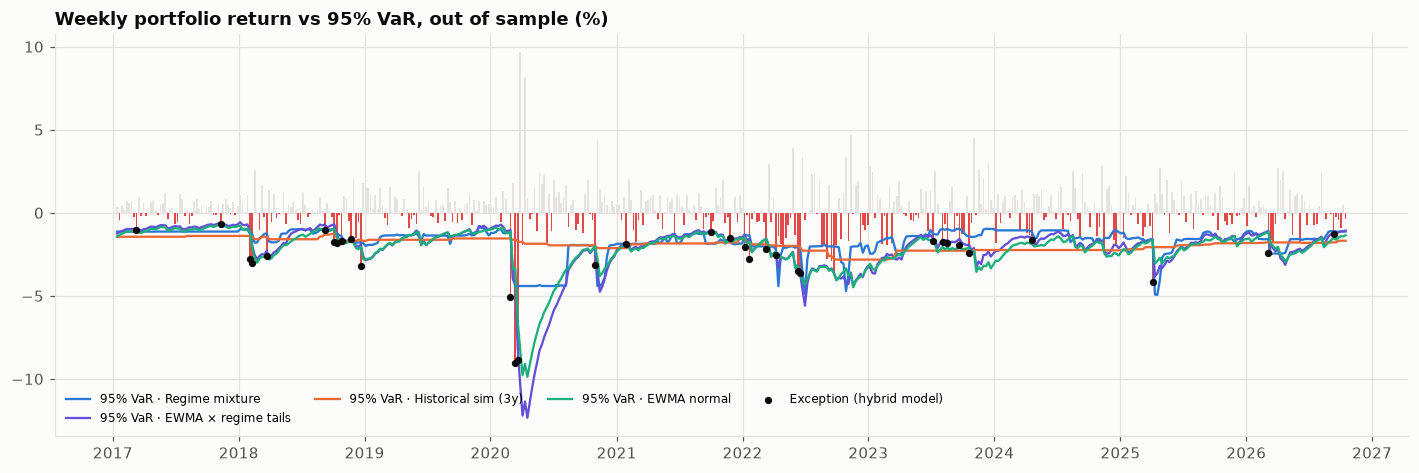

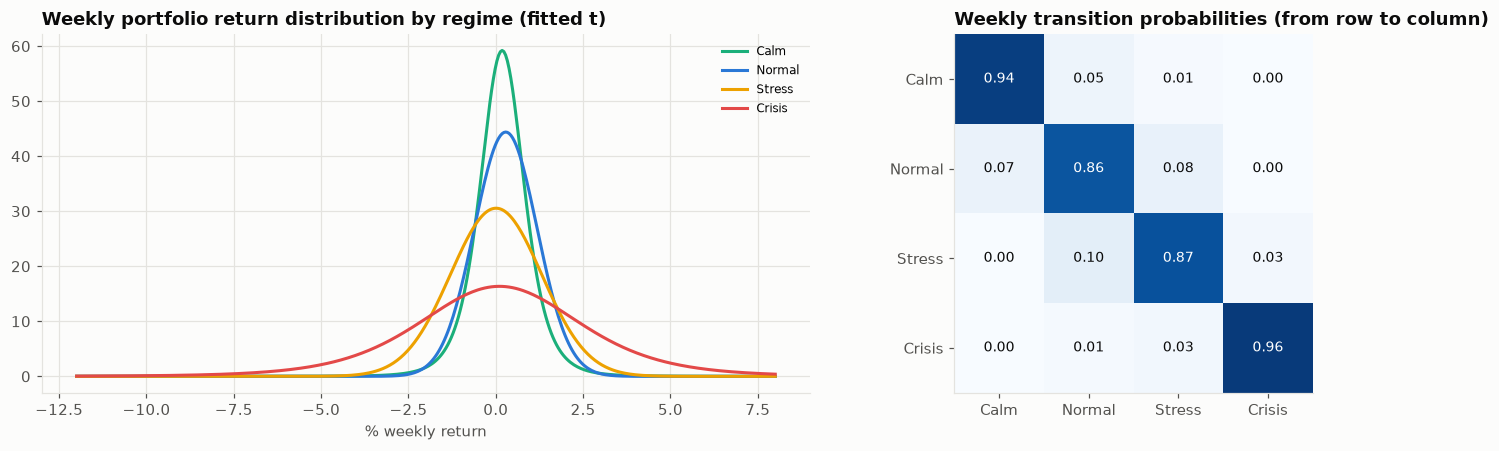

Next-week 99% VaR ($mm): Regime mixture 1.95, EWMA × regime tails 1.87, Historical sim (3y) 2.41, EWMA normal 1.91


In [10]:
# --- Chart 2: weekly P&L vs the three 95% VaR forecasts
fig, ax = plt.subplots(figsize=(13, 4.4))
ax.bar(
    realised.index,
    realised * 100,
    width=5,
    color=[STATUS["red"] if v < 0 else GRID for v in realised],
)
for (m, a), v in var.items():
    if a == 0.95:
        ax.plot(
            v.index,
            -v * 100,
            lw=1.5,
            label=f"95% VaR · {m}",
            color={
                "Regime mixture": PALETTE[0],
                "EWMA × regime tails": PALETTE[6],
                "Historical sim (3y)": PALETTE[1],
                "EWMA normal": PALETTE[2],
            }[m],
        )
exc = realised < -var[("EWMA × regime tails", 0.95)]
ax.scatter(
    realised.index[exc],
    realised[exc] * 100,
    s=14,
    color=INK,
    zorder=3,
    label="Exception (hybrid model)",
)
ax.set_title("Weekly portfolio return vs 95% VaR, out of sample (%)")
ax.legend(fontsize=8, ncol=4, loc="lower left")
plt.tight_layout()
save_fig(fig, "02_weekly_var_backtest")
plt.show()

# --- Chart 3: what each regime's return distribution looks like
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.4, 1]}
)
x = np.linspace(-0.12, 0.08, 400)
for k, name in enumerate(NAMES):
    axes[0].plot(
        x * 100,
        stats.t.pdf(x, *reg_t[k]),
        color=REGIME_COLORS[k],
        lw=2,
        label=f"{name}",
    )
axes[0].set_title("Weekly portfolio return distribution by regime (fitted t)")
axes[0].set_xlabel("% weekly return")
axes[0].legend(fontsize=8)
im = axes[1].imshow(A, cmap="Blues", vmin=0, vmax=1)
for (i, j), v in np.ndenumerate(A):
    axes[1].text(
        j,
        i,
        f"{v:.2f}",
        ha="center",
        va="center",
        color="white" if v > 0.5 else INK,
        fontsize=9,
    )
axes[1].set_xticks(range(K), NAMES)
axes[1].set_yticks(range(K), NAMES)
axes[1].set_title("Weekly transition probabilities (from row to column)")
axes[1].grid(False)
plt.tight_layout()
save_fig(fig, "03_regime_distributions_and_transitions")
plt.show()

today = {
    m: v.iloc[-1] * PORTFOLIO_USD / 1e6
    for (m, a), v in var.items()
    if a == 0.99
}
print(
    "Next-week 99% VaR ($mm): "
    + ", ".join(f"{m} {v:.2f}" for m, v in today.items())
)
regimes.to_csv(OUT_DIR / "regime_statistics.csv")
bt.to_csv(OUT_DIR / "weekly_var_backtest.csv")
filt.to_csv(OUT_DIR / "filtered_regime_probabilities.csv")

## 8. Reading the results and limitations

**Four regimes, economically distinct and persistent.** BIC picks four states. Volatility, the VIX and credit-spread widening rise together from "Calm" to "Crisis", and the portfolio's loss distribution widens with them. Calm spells last months; crisis spells are rarer but sticky. The memory-less Gaussian mixture switches state more than twice as often for the same data, so the Markov structure is doing real work.

**As a stand-alone VaR engine, the pure regime mixture fails.** It has roughly twice the expected exceptions. Regimes are identified with a lag, and when stress arrives suddenly (February 2020, the 2022 stock–bond sell-off) the predicted probabilities still point to the calm regime for a week or two. A regime label is a slow variable, while VaR needs a fast one.

**Combine them: EWMA for the level, regimes for the shape.** The hybrid takes the volatility level from EWMA and the tail shape from the regime model. It is the only model that passes both the coverage and the independence tests at both 95% and 99%.

EWMA normal under-covers at 99% (its tails are too thin), and historical simulation has the right count but clustered exceptions. In stressed weeks the hybrid carries the largest VaR, which is when it is needed.

- **Today** the filter puts most of the probability on the normal regime, and the hybrid's 99% weekly VaR is close to the EWMA level.

**Limitations**

- **Annual re-estimation.** Parameters are refreshed once a year; within the year a structural change (2022's stock–bond correlation flip) is only seen through the filter.
- **Gaussian emissions** for the features; within-regime return tails come from a Student-t fitted separately.
- **Label switching and the number of states** are model-selection choices. BIC is one criterion; stability across random starts is another.

## References

### Finance and regulation

- Hamilton, J. D. (1989). A new approach to the economic analysis of nonstationary time series and the business cycle. *Econometrica, 57*(2), 357–384. https://doi.org/10.2307/1912559
- Ang, A., & Bekaert, G. (2002). International asset allocation with regime shifts. *The Review of Financial Studies, 15*(4), 1137–1187. https://doi.org/10.1093/rfs/15.4.1137
- Guidolin, M., & Timmermann, A. (2007). Asset allocation under multivariate regime switching. *Journal of Economic Dynamics and Control, 31*(11), 3503–3544. https://doi.org/10.1016/j.jedc.2006.12.004
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *The Journal of Derivatives, 3*(2), 73–84. https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review, 39*(4), 841–862. https://doi.org/10.2307/2527341

### Machine learning and deep learning

- Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE, 77*(2), 257–286. https://doi.org/10.1109/5.18626
- McLachlan, G., & Peel, D. (2000). *Finite mixture models*. Wiley. https://doi.org/10.1002/0471721182
- Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of Statistics, 6*(2), 461–464. https://doi.org/10.1214/aos/1176344136